# Costo computacional — complejidad, perfilamiento y optimización

El experimento completo (136 combinaciones con validación anidada 5 × 3 y 40 evaluaciones por búsqueda) consumió **16.6 horas de CPU**. Este notebook analiza ese costo desde cuatro ángulos:

1. **Dónde se fue el tiempo:** qué modelos y decisiones concentran el cómputo.
2. **Complejidad:** el costo teórico de cada algoritmo y cómo crece en la práctica con el tamaño de los datos (escalamiento empírico en escala log-log).
3. **Perfilamiento:** qué etapas del pipeline y qué funciones consumen el tiempo (medición por etapas y `cProfile`).
4. **Optimización:** qué decisiones de implementación hacen viable el experimento, comparando en cada caso la versión estándar con la optimizada (paralelismo, orden de las tareas, algoritmos más eficientes, grilla adaptativa, reutilización de resultados).

Los tiempos dependen del equipo, que se reporta abajo. Las mediciones se guardan en `experiments/costo/`; con `RECALCULAR = True` se repiten (≈ 10 minutos). Figuras `fig28`–`fig32` y tablas `tabla23`–`tabla28`.

In [1]:
import pickle
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from joblib import Parallel, delayed
from scipy.optimize import curve_fit
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from IPython.display import display

warnings.filterwarnings("ignore")
%matplotlib inline

RUTA_MODELADO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RUTA_MODELADO) not in sys.path:
    sys.path.insert(0, str(RUTA_MODELADO))

from src import config
from src.costo import (COMPLEJIDAD, RUTA_COSTO, ajustes_validacion_anidada, cronometrar, escalamiento,
                       pendiente_loglog, perfilar, planificar, remuestrear, tamano_en_memoria, tiempos_por_etapa)
from src.data_prep import preparar_dataset, separar_X_y
from src.entorno import equipo, versiones
from src.graficos import (AQUA, AZUL, EJE, FONDO, NARANJA, ROJO, TINTA, TINTA_2, TINTA_3, aplicar_estilo, corto,
                          encabezado, guardar, guardar_tabla)
from src.model_factory import ESPACIOS_CLASIFICACION, ESPACIOS_REGRESION
from src.nested_cv import _peso_tarea
from src.optimizers import _valores_continuos, espacio_a_grid
from src.predicciones import (RUTA_PREDICCIONES, construir_modelo, parsear_hiperparametros, particiones_externas,
                              predecir_fold, tareas_desde_log)
from src.seleccion import CLAVES, cargar_log, mejor_por_modelo, resumir

aplicar_estilo()
RUTA_COSTO.mkdir(parents=True, exist_ok=True)
RECALCULAR = False


def medido(nombre, funcion):
    ruta = RUTA_COSTO / f"{nombre}.csv"
    if ruta.exists() and not RECALCULAR:
        return pd.read_csv(ruta)
    tabla = funcion()
    tabla.to_csv(ruta, index=False)
    return tabla


display(versiones(["numpy", "scikit-learn", "imbalanced-learn", "xgboost", "joblib", "shap"]).set_index("paquete").T)
display(pd.Series(equipo(), name="equipo").to_frame())

paquete,python,numpy,scikit-learn,imbalanced-learn,xgboost,joblib,shap
versión,3.12.14,2.4.4,1.8.0,0.14.2,3.4.1,1.6.0,0.52.0


,equipo
sistema,Windows-11-10.0.26200-SP0
procesador,AMD Ryzen 5 5600GT with Radeon Graphics
núcleos lógicos,12
núcleos físicos,6
memoria RAM (GB),15.8
procesos en paralelo (N_WORKERS),11


## 1. Dónde se fue el tiempo del experimento

Cada fila del log es un fold externo: una búsqueda de hiperparámetros con 3 folds internos más el reentrenamiento final. El número de modelos entrenados por combinación es K_ext · (E · K_int + 1), con E evaluaciones de la búsqueda.

Tiempo total: 16.6 h de CPU · 79,505 modelos entrenados (máximo teórico por combinación con E = 40: 605)


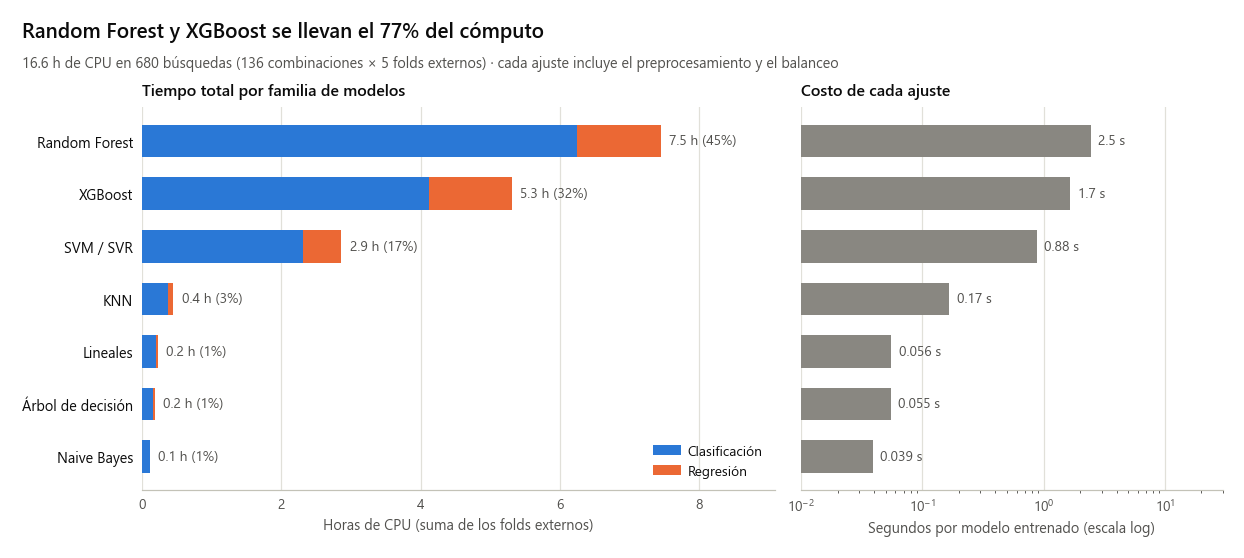

Segundos por ajuste según el balanceo (clasificación):


balanceo,sin_balanceo,class_weight,SMOTE,ADASYN
modelo,,,,
Decision Tree,0.037,0.039,0.070,0.100
KNN,0.121,NaN,0.202,0.232
Naive Bayes,0.026,0.027,0.037,0.066
Random Forest,1.787,1.908,3.223,3.399
Regresión Logística (L1/L2),0.082,0.049,0.065,0.092
SVM,0.418,0.582,1.240,1.290
XGBoost,0.744,1.192,2.232,2.279


In [2]:
log_clf, log_reg = cargar_log("clasificacion"), cargar_log("regresion")
log = pd.concat([log_clf, log_reg], ignore_index=True)
log["ajustes"] = log["n_evaluaciones"] * config.K_INNER + 1
FAMILIA = {"SVM": "SVM / SVR", "SVR": "SVM / SVR", "Regresión Logística (L1/L2)": "Lineales", "Ridge": "Lineales",
           "Lasso": "Lineales", "Decision Tree": "Árbol de decisión"}
log["familia"] = log["modelo"].map(lambda m: FAMILIA.get(m, m))

horas = log.pivot_table(index="familia", columns="tarea", values="tiempo_seg", aggfunc="sum").fillna(0) / 3600
horas = horas.loc[horas.sum(axis=1).sort_values(ascending=False).index]
seg_por_ajuste = (log.groupby("familia")["tiempo_seg"].sum() / log.groupby("familia")["ajustes"].sum()).reindex(horas.index)
total_h = horas.to_numpy().sum()
print(f"Tiempo total: {total_h:.1f} h de CPU · {log['ajustes'].sum():,} modelos entrenados "
      f"(máximo teórico por combinación con E = 40: {ajustes_validacion_anidada():,})")

fig, (ax_h, ax_s) = plt.subplots(1, 2, figsize=(11, 4.2), width_ratios=[1.5, 1], layout="constrained")
y = np.arange(len(horas))[::-1]
izquierda = np.zeros(len(horas))
for tarea, color, etiqueta in [("clasificacion", AZUL, "Clasificación"), ("regresion", NARANJA, "Regresión")]:
    ax_h.barh(y, horas[tarea], left=izquierda, height=0.62, color=color, label=etiqueta, zorder=2)
    izquierda += horas[tarea].to_numpy()
for yi, total in zip(y, horas.sum(axis=1)):
    ax_h.text(total + 0.12, yi, f"{total:.1f} h ({total / total_h:.0%})", va="center", fontsize=9, color=TINTA_2)
ax_h.set_yticks(y, labels=horas.index)
ax_h.tick_params(axis="y", labelcolor=TINTA)
ax_h.set(xlabel="Horas de CPU (suma de los folds externos)", title="Tiempo total por familia de modelos")
ax_h.grid(axis="x")
ax_h.set_axisbelow(True)
ax_h.spines["left"].set_visible(False)
ax_h.legend(loc="lower right")
ax_h.margins(x=0.22)

ax_s.barh(y, seg_por_ajuste, height=0.62, color=TINTA_3, zorder=2)
for yi, s in zip(y, seg_por_ajuste):
    ax_s.text(s * 1.15, yi, f"{s:.2g} s", va="center", fontsize=9, color=TINTA_2)
ax_s.set_xscale("log")
ax_s.set_yticks(y, labels=[])
ax_s.set(xlabel="Segundos por modelo entrenado (escala log)", title="Costo de cada ajuste", xlim=(0.01, 30))
ax_s.grid(axis="x")
ax_s.set_axisbelow(True)
ax_s.spines["left"].set_visible(False)
participacion = horas.loc[["Random Forest", "XGBoost"]].to_numpy().sum() / total_h
encabezado(fig, f"Random Forest y XGBoost se llevan el {participacion:.0%} del cómputo",
           f"{total_h:.1f} h de CPU en {len(log)} búsquedas (136 combinaciones × 5 folds externos) · cada ajuste incluye el preprocesamiento y el balanceo")
guardar(fig, "fig28_costo_por_modelo")
plt.show()

por_balanceo = (log_clf.assign(ajustes=log_clf["n_evaluaciones"] * config.K_INNER + 1)
                .groupby(["modelo", "balanceo"]).apply(lambda g: g["tiempo_seg"].sum() / g["ajustes"].sum())
                .unstack().reindex(columns=["sin_balanceo", "class_weight", "SMOTE", "ADASYN"]))
print("Segundos por ajuste según el balanceo (clasificación):")
display(por_balanceo.round(3))

> **Resultado:** Random Forest (45%) y XGBoost (32%) concentran el 77% del tiempo y SVM/SVR otro 17%; los modelos lineales, el árbol y Naive Bayes juntos no llegan al 3%. Cualquier optimización vale la pena sobre todo en los ensambles. El costo medio de un ajuste (incluyendo preprocesamiento y balanceo) va de 0.04 s en Naive Bayes a 2.5 s en Random Forest, casi dos órdenes de magnitud. El balanceo por sobremuestreo encarece cada ajuste porque agrega vinos sintéticos hasta igualar las clases: con SMOTE o ADASYN el conjunto de entrenamiento pasa de ≈ 4,250 a ≈ 6,900 filas y el Random Forest tarda ≈ 1.6–1.8 veces más que con `class_weight`, que no cambia el tamaño de los datos.

## 2. Complejidad teórica

Notación: n = filas de entrenamiento (≈ 4,256 en cada fold externo, ≈ 2,840 en cada fold interno), d = variables (13 tras el one-hot), T = árboles, m = variables candidatas por división, p = profundidad, b = intervalos del histograma de XGBoost, n_sv = vectores de soporte.

In [3]:
tabla23 = COMPLEJIDAD.copy()
guardar_tabla(tabla23, "tabla23_complejidad_teorica")
display(tabla23)
print(f"Validación anidada: K_ext · (E · K_int + 1) = {config.K_OUTER} · ({config.PRESUPUESTO_EVALUACIONES} · "
      f"{config.K_INNER} + 1) = {ajustes_validacion_anidada()} ajustes por combinación como máximo; "
      f"136 combinaciones → hasta {136 * ajustes_validacion_anidada():,} ajustes (en la práctica {log['ajustes'].sum():,}, "
      f"porque la grilla adaptativa usa menos de 40 puntos en algunos modelos).")

,modelo,entrenamiento,predicción por caso,memoria del modelo,qué lo encarece
0,KNN,O(d·n·log n) (árbol KD) u O(1) (fuerza bruta),O(n·d) fuerza bruta; ≈ O(d·log n) con árbol,O(n·d): guarda los datos,n (no k)
1,Naive Bayes,O(n·d),O(d),O(d),—
2,Regresión logística / Ridge / Lasso,O(n·d·iteraciones),O(d),O(d),C o alpha (iteraciones)
3,Árbol de decisión,O(d·n·log n),O(p),O(hojas),"max_depth, min_samples_leaf"
4,Random Forest,O(T·m·n·log n),O(T·p),O(T·hojas),"n_estimators, max_features"
5,XGBoost (hist),O(T·(n·d + 2ᵖ·b)),O(T·p),O(T·2ᵖ),"n_estimators, max_depth"
6,SVM / SVR (RBF),entre O(n²·d) y O(n³·d),O(n_sv·d),O(n_sv·d),"C, gamma, n"
7,SMOTE / ADASYN,O(n_min·log n·d) (vecinos con árbol),—,—,"n_min, k = 5"


Validación anidada: K_ext · (E · K_int + 1) = 5 · (40 · 3 + 1) = 605 ajustes por combinación como máximo; 136 combinaciones → hasta 82,280 ajustes (en la práctica 79,505, porque la grilla adaptativa usa menos de 40 puntos en algunos modelos).


## 3. Escalamiento empírico

Para contrastar la teoría con la práctica se mide el tiempo de entrenamiento y de predicción de cada modelo (con los hiperparámetros elegidos en el primer fold externo y sin balanceo, para aislar el costo del modelo) con muestras de 500 a 16,000 vinos. Hasta 4,000 se usan submuestras del entrenamiento; para 8,000 y 16,000 se remuestrea con reemplazo agregando un ruido del 1% de la desviación estándar, solo para medir tiempos. La predicción siempre es sobre los mismos 1,064 vinos de prueba. Cada punto es la mediana de 3 repeticiones, en un solo proceso. El **exponente empírico** es la pendiente en escala log-log (tiempo ∝ n^k), calculada con n ≥ 2,000 para que no la dominen los costos fijos.

In [4]:
X, y_reg, y_clf = separar_X_y(preparar_dataset(verbose=False))
tr0, te0 = particiones_externas("clasificacion", X, y_clf)[0]
X_tr, y_tr, X_te, y_te = X.iloc[tr0].reset_index(drop=True), y_clf.iloc[tr0].reset_index(drop=True), X.iloc[te0], y_clf.iloc[te0]
mejores = mejor_por_modelo(resumir(log_clf, "clasificacion"))


def hiperparametros(log, modelo, balanceo, optimizador, fold=0):
    fila = log[(log["modelo"] == modelo) & (log["balanceo"] == balanceo) & (log["optimizador"] == optimizador)
               & (log["fold_externo"] == fold)].iloc[0]
    return parsear_hiperparametros(fila["mejores_hiperparametros"])


HP = {f.modelo: hiperparametros(log_clf, f.modelo, f.balanceo, f.optimizador) for f in mejores.itertuples()}
TAMANOS = [500, 1000, 2000, 4000, 8000, 16000]


def medir_escalamiento():
    from imblearn.over_sampling import ADASYN, SMOTE
    from src.data_prep import construir_preprocesador
    partes = [escalamiento("clasificacion", modelo, "sin_balanceo", h, X_tr, y_tr, TAMANOS, X_te, repeticiones=3)
              for modelo, h in HP.items()]
    for nombre, muestreador in [("SMOTE", SMOTE), ("ADASYN", ADASYN)]:
        filas = []
        for n in TAMANOS:
            Xn, yn = remuestrear(X_tr, y_tr, n)
            Xt = construir_preprocesador().fit_transform(Xn)
            t = cronometrar(lambda: muestreador(random_state=config.RANDOM_STATE).fit_resample(Xt, yn), 3)
            filas.append({"modelo": f"{nombre} (solo remuestreo)", "balanceo": "—", "n": n, "t_fit_s": t, "t_pred_s": np.nan})
        partes.append(pd.DataFrame(filas))
    return pd.concat(partes, ignore_index=True)


escala = medido("escalamiento", medir_escalamiento)
ESPERADO = {"KNN": "≈ 1 (árbol KD); predicción ≈ 0.5–1", "Naive Bayes": "1", "Regresión Logística (L1/L2)": "≈ 1",
            "Decision Tree": "≈ 1–1.2 (n log n)", "Random Forest": "≈ 1–1.2 (n log n)", "XGBoost": "≤ 1 (histograma)",
            "SVM": "2–3", "SMOTE (solo remuestreo)": "≈ 1–1.2", "ADASYN (solo remuestreo)": "≈ 1–1.2"}
filas = []
for modelo, g in escala.groupby("modelo", sort=False):
    grande = g[g["n"] >= 2000]
    filas.append({"modelo": modelo, "exponente_ajuste": pendiente_loglog(grande["n"], grande["t_fit_s"]),
                  "exponente_ajuste_todo_el_rango": pendiente_loglog(g["n"], g["t_fit_s"]),
                  "exponente_prediccion": pendiente_loglog(grande["n"], grande["t_pred_s"]) if g["t_pred_s"].notna().all() else np.nan,
                  "esperado_ajuste": ESPERADO.get(modelo, ""),
                  "t_ajuste_n4000_s": g.loc[g["n"] == 4000, "t_fit_s"].iloc[0],
                  "t_ajuste_n16000_s": g.loc[g["n"] == 16000, "t_fit_s"].iloc[0]})
tabla24 = pd.DataFrame(filas)
guardar_tabla(tabla24.round(4), "tabla24_escalamiento_empirico")
display(tabla24.round(3))

,modelo,exponente_ajuste,exponente_ajuste_todo_el_rango,exponente_prediccion,esperado_ajuste,t_ajuste_n4000_s,t_ajuste_n16000_s
0,Random Forest,1.093,0.872,-0.018,≈ 1–1.2 (n log n),1.711,9.875
1,XGBoost,0.717,0.659,0.021,≤ 1 (histograma),0.450,1.249
2,SVM,1.983,1.742,0.947,2–3,0.176,2.910
3,KNN,0.623,0.461,0.681,≈ 1 (árbol KD); predicción ≈ 0.5–1,0.009,0.027
4,Regresión Logística (L1/L2),0.601,0.464,-0.070,≈ 1,0.010,0.026
5,Decision Tree,1.389,1.000,-0.021,≈ 1–1.2 (n log n),0.015,0.136
6,Naive Bayes,0.465,0.266,0.027,1,0.005,0.013
7,SMOTE (solo remuestreo),1.244,1.019,NaN,≈ 1–1.2,0.008,0.046
8,ADASYN (solo remuestreo),1.196,1.194,NaN,≈ 1–1.2,0.034,0.155


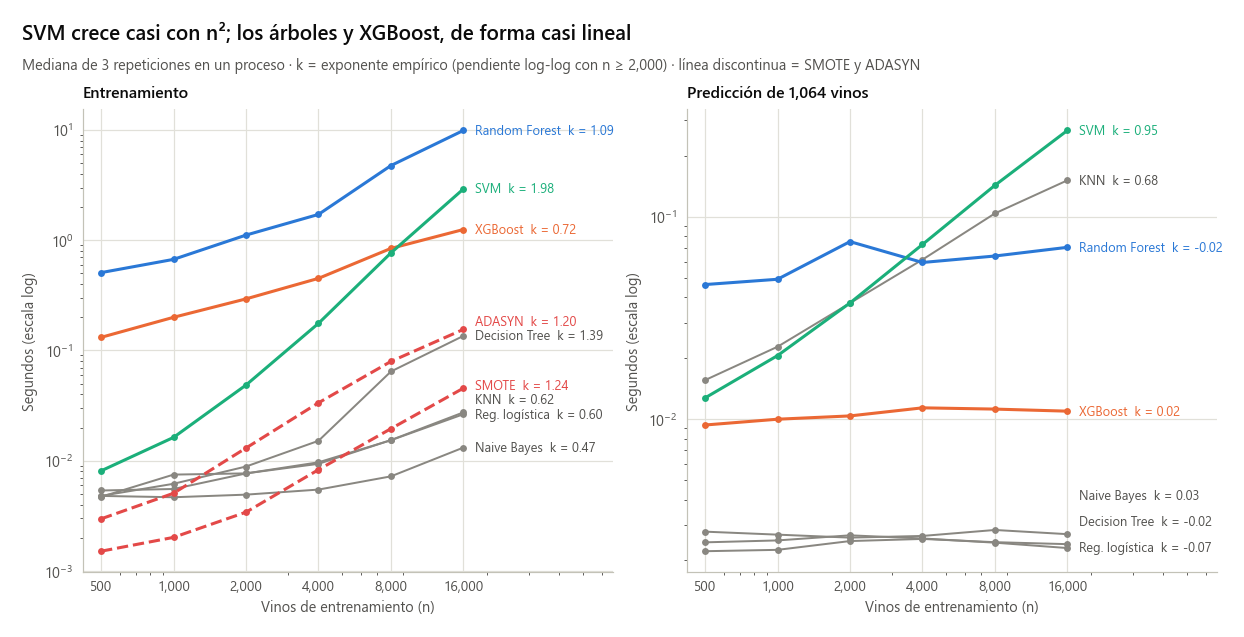

In [5]:
def separar_etiquetas(valores, minimo):
    orden = np.argsort(valores)
    pos = np.log10(np.asarray(valores, float))
    ajustadas = pos.copy()
    for k in range(1, len(orden)):
        anterior, actual = orden[k - 1], orden[k]
        ajustadas[actual] = max(ajustadas[actual], ajustadas[anterior] + minimo)
    return 10 ** ajustadas


COLOR = {"Random Forest": AZUL, "XGBoost": NARANJA, "SVM": AQUA, "SMOTE (solo remuestreo)": ROJO,
         "ADASYN (solo remuestreo)": ROJO}
fig, (ax_f, ax_p) = plt.subplots(1, 2, figsize=(11, 4.9), layout="constrained")
for ax, columna, titulo in [(ax_f, "t_fit_s", "Entrenamiento"), (ax_p, "t_pred_s", "Predicción de 1,064 vinos")]:
    finales, nombres = [], []
    for modelo, g in escala.groupby("modelo", sort=False):
        if g[columna].isna().all():
            continue
        color = COLOR.get(modelo, TINTA_3)
        destacado = modelo in COLOR
        ax.plot(g["n"], g[columna], "-o", color=color, lw=2 if destacado else 1.3, ms=3.5, zorder=3 if destacado else 2,
                ls="--" if "remuestreo" in modelo else "-")
        k = tabla24.loc[tabla24["modelo"] == modelo, "exponente_ajuste" if columna == "t_fit_s" else "exponente_prediccion"].iloc[0]
        finales.append(g[columna].iloc[-1])
        nombres.append((f"{corto(modelo).replace(' (solo remuestreo)', '')}  k = {k:.2f}", color))
    for y_pos, (texto, color) in zip(separar_etiquetas(finales, 0.13), nombres):
        ax.text(16000 * 1.12, y_pos, texto, va="center", fontsize=8.4, color=color if color != TINTA_3 else TINTA_2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(TAMANOS, labels=[f"{n:,}" for n in TAMANOS])
    ax.set(xlabel="Vinos de entrenamiento (n)", ylabel="Segundos (escala log)", title=titulo, xlim=(420, 16000 * 4.2))
    ax.grid(True, which="major")
    ax.set_axisbelow(True)
encabezado(fig, "SVM crece casi con n²; los árboles y XGBoost, de forma casi lineal",
           "Mediana de 3 repeticiones en un proceso · k = exponente empírico (pendiente log-log con n ≥ 2,000) · línea discontinua = SMOTE y ADASYN")
guardar(fig, "fig29_escalamiento_empirico")
plt.show()

> **Resultado:** las mediciones respaldan la teoría. SVM es el único con crecimiento claramente superlineal (exponente ≈ 2 en el entrenamiento, coherente con O(n²) a O(n³)): duplicar los datos cuadruplica su tiempo, y su predicción también crece con n porque el número de vectores de soporte aumenta. Random Forest (k = 1.09) y el árbol de decisión (1.39) crecen algo más que linealmente (≈ n log n, y además los árboles se hacen más profundos con más datos), mientras que XGBoost con histogramas escala por debajo de lo lineal en este rango (0.72) porque buena parte de su costo es fijo por árbol. KNN casi no tarda en entrenar (solo arma el árbol KD), pero su predicción crece con n (0.68) porque cada consulta recorre más vecinos candidatos. En los modelos más baratos (Naive Bayes, regresión logística) el exponente sale menor que 1 porque, con tiempos de milisegundos, dominan los costos fijos (validaciones, conversión de datos) y no el algoritmo. SMOTE y ADASYN cuestan milisegundos, lo cual confirma que el sobrecosto del balanceo no viene del remuestreo en sí sino de entrenar el modelo con más filas. Con los ≈ 4,000 vinos de este problema todos los modelos entrenan en menos de 2 segundos; si el conjunto creciera 10 veces, SVM sería el primero en volverse inviable.

## 4. Perfilamiento

### 4.1 Tiempo por etapa del pipeline

Cada pipeline tiene cuatro etapas: preprocesar (escalado y one-hot), balancear (aquí SMOTE), ajustar el modelo y predecir. Se miden por separado sobre el entrenamiento del primer fold externo (4,256 vinos), con los mismos hiperparámetros de antes.

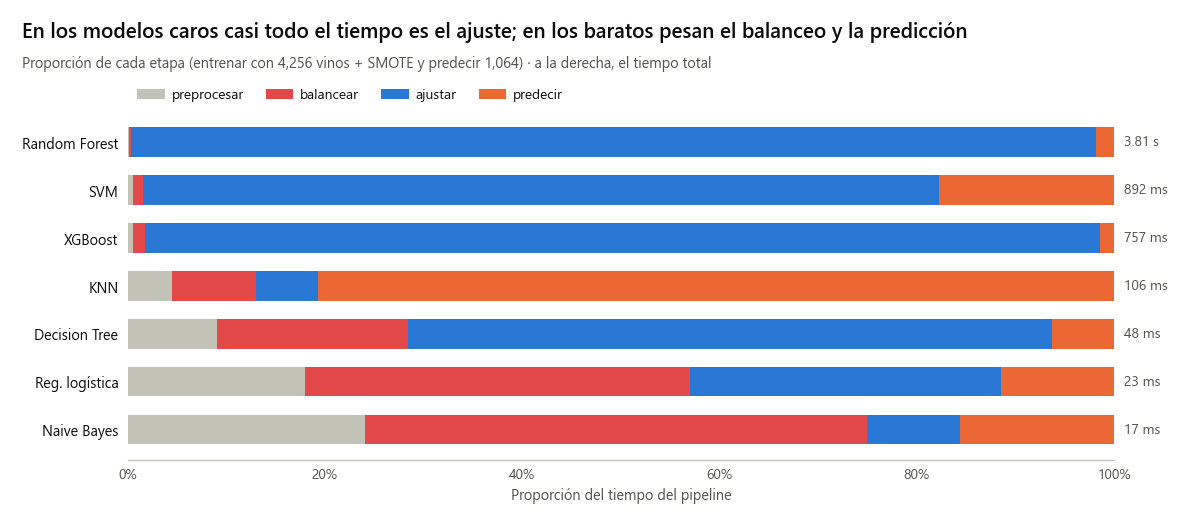

,modelo,balanceo,preprocesar_ms,balancear_ms,ajustar_ms,predecir_ms,total_ms
0,Naive Bayes,SMOTE,4.2,8.9,1.6,2.7,17.5
1,Regresión Logística (L1/L2),SMOTE,4.2,9.0,7.3,2.6,23.1
2,Decision Tree,SMOTE,4.3,9.2,31.1,3.0,47.7
3,KNN,SMOTE,4.7,9.1,6.6,85.6,106.1
4,XGBoost,SMOTE,4.4,9.0,732.5,10.9,756.8
5,SVM,SMOTE,4.8,9.1,719.7,158.0,891.6
6,Random Forest,SMOTE,5.2,9.3,3725.6,68.2,3808.4


In [6]:
def medir_etapas():
    return pd.DataFrame([tiempos_por_etapa("clasificacion", modelo, "SMOTE", h, X_tr, y_tr, X_te, repeticiones=5)
                         for modelo, h in HP.items()])


etapas = medido("etapas", medir_etapas)
ETAPAS = ["preprocesar", "balancear", "ajustar", "predecir"]
etapas["total"] = etapas[ETAPAS].sum(axis=1)
etapas = etapas.sort_values("total").reset_index(drop=True)
composicion = etapas[ETAPAS].div(etapas["total"], axis=0)

fig, ax = plt.subplots(figsize=(10.5, 3.9), layout="constrained")
y = np.arange(len(etapas))
izquierda = np.zeros(len(etapas))
colores = {"preprocesar": EJE, "balancear": ROJO, "ajustar": AZUL, "predecir": NARANJA}
for etapa in ETAPAS:
    ax.barh(y, composicion[etapa], left=izquierda, height=0.62, color=colores[etapa], label=etapa, zorder=2)
    izquierda += composicion[etapa].to_numpy()
for yi, total in zip(y, etapas["total"]):
    ax.text(1.01, yi, f"{total * 1000:,.0f} ms" if total < 1 else f"{total:.2f} s", va="center", fontsize=9, color=TINTA_2,
            transform=ax.get_yaxis_transform())
ax.set_yticks(y, labels=[corto(m) for m in etapas["modelo"]])
ax.tick_params(axis="y", labelcolor=TINTA)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Proporción del tiempo del pipeline")
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.3)
ax.spines["left"].set_visible(False)
encabezado(fig, "En los modelos caros casi todo el tiempo es el ajuste; en los baratos pesan el balanceo y la predicción",
           "Proporción de cada etapa (entrenar con 4,256 vinos + SMOTE y predecir 1,064) · a la derecha, el tiempo total")
guardar(fig, "fig30_tiempo_por_etapa")
plt.show()
display(etapas.assign(**{e: etapas[e] * 1000 for e in ETAPAS + ["total"]}).round(1)
        .rename(columns={e: f"{e}_ms" for e in ETAPAS + ["total"]}))

### 4.2 Perfil de funciones con `cProfile`

La unidad de trabajo de la búsqueda es una **evaluación**: entrenar y evaluar una configuración en los 3 folds internos (`cross_val_score`). Se perfila una evaluación de las dos combinaciones más caras, Random Forest + ADASYN y XGBoost + SMOTE, y se listan las funciones con más tiempo propio (el tiempo dentro de la función, sin contar las que llama).

In [7]:
cv_interno = StratifiedKFold(n_splits=config.K_INNER, shuffle=True, random_state=config.RANDOM_STATE)
PERFILES = {"Random Forest + ADASYN": ("Random Forest", "ADASYN", HP["Random Forest"]),
            "XGBoost + SMOTE": ("XGBoost", "SMOTE", HP["XGBoost"])}


def categoria(fila):
    texto = f"{fila['funcion']} {fila['archivo']}".lower()
    if "tree/_classes" in texto or "_tree" in texto or "builder" in texto:
        return "construcción de árboles (Cython)"
    if "xgboost" in texto or "xgbooster" in texto:
        return "XGBoost (C++)"
    if "over_sampling" in texto or "neighbors" in texto:
        return "remuestreo / vecinos"
    if "inspect" in texto or "validation" in texto or "_param_validation" in texto or "base.py" in texto or "signature" in texto:
        return "validación y clonado (Python)"
    if "parallel" in texto or "joblib" in texto:
        return "joblib (sobrecosto)"
    return "otros"


def medir_perfiles():
    partes = []
    for nombre, (modelo, balanceo, h) in PERFILES.items():
        pipe = construir_modelo("clasificacion", modelo, balanceo, h)
        tabla, total = perfilar(lambda: cross_val_score(pipe, X_tr, y_tr, cv=cv_interno, scoring="roc_auc"), top=None)
        partes.append(tabla.assign(perfil=nombre, total_s=total))
    return pd.concat(partes, ignore_index=True)


perfiles = medido("perfiles", medir_perfiles)
perfiles["categoria"] = perfiles.apply(categoria, axis=1)


def descomponer(perfil):
    total = perfil["total_s"].iloc[0]

    def tiempo(funcion, archivo, columna="tiempo_acumulado_s"):
        filas = perfil[(perfil["funcion"] == funcion) & perfil["archivo"].str.contains(archivo, regex=False)]
        return float(filas[columna].max()) if len(filas) else 0.0

    if tiempo("_fit", "tree/_classes.py", "tiempo_propio_s") > 0:
        nucleo = tiempo("_fit", "tree/_classes.py", "tiempo_propio_s")
        ajuste = tiempo("fit", "ensemble/_forest.py")
        nombre_nucleo = "construcción de los árboles (Cython)"
    else:
        nucleo = tiempo("update", "xgboost/core.py")
        ajuste = tiempo("fit", "xgboost/sklearn.py")
        nombre_nucleo = "boosting en C++ (XGBoosterUpdateOneIter)"
    etapas = {nombre_nucleo: nucleo,
              "resto del ajuste en Python (validación, semillas, joblib por árbol)": ajuste - nucleo,
              "remuestreo (ADASYN / SMOTE)": tiempo("fit_resample", "imblearn/base.py"),
              "preprocesamiento (escalado y one-hot)": tiempo("fit_transform", "compose/_column_transformer.py"),
              "predicción y AUC de los 3 folds": tiempo("_score", "model_selection/_validation.py")}
    etapas["validación cruzada y clonado"] = total - sum(etapas.values())
    return pd.DataFrame({"etapa": list(etapas), "segundos": list(etapas.values())}).assign(
        porcentaje=lambda t: 100 * t["segundos"] / total)


partes = []
for nombre, g in perfiles.groupby("perfil", sort=False):
    print(f"{nombre}: {g['total_s'].iloc[0]:.2f} s por evaluación (3 ajustes + 3 predicciones) · "
          f"{len(g):,} funciones distintas en el perfil · las 8 con más tiempo propio:")
    display(g[["funcion", "archivo", "llamadas", "tiempo_propio_s", "tiempo_acumulado_s", "%_del_total"]].head(8).round(3))
    partes.append(descomponer(g).assign(perfil=nombre))
tabla25 = pd.concat(partes, ignore_index=True)[["perfil", "etapa", "segundos", "porcentaje"]]
guardar_tabla(tabla25.round(4), "tabla25_perfil_por_etapa")
display(tabla25.round(2))

Random Forest + ADASYN: 9.31 s por evaluación (3 ajustes + 3 predicciones) · 1,057 funciones distintas en el perfil · las 8 con más tiempo propio:


,funcion,archivo,llamadas,tiempo_propio_s,tiempo_acumulado_s,%_del_total
0,_fit,sklearn/tree/_classes.py,1272,6.558,7.583,70.432
1,check_random_state,sklearn/utils/validation.py,3823,0.230,0.487,2.470
2,inner,numpy/_core/_ufunc_config.py,2551,0.217,0.223,2.334
3,_signature_from_function,inspect.py,7744,0.144,0.462,1.543
4,predict_proba,sklearn/tree/_classes.py,1272,0.137,0.168,1.475
5,__call__,sklearn/utils/parallel.py,2565,0.130,9.295,1.399
6,__init__,inspect.py,98798,0.107,0.194,1.154
7,_generate_sample_indices,sklearn/ensemble/_forest.py,1272,0.086,0.370,0.928


XGBoost + SMOTE: 2.12 s por evaluación (3 ajustes + 3 predicciones) · 1,142 funciones distintas en el perfil · las 8 con más tiempo propio:


,funcion,archivo,llamadas,tiempo_propio_s,tiempo_acumulado_s,%_del_total
1057,update,xgboost/core.py,1440,1.746,1.796,82.267
1058,__init__,xgboost/core.py,3,0.099,0.099,4.669
1059,reset,xgboost/core.py,3,0.042,0.042,1.978
1060,inplace_predict,xgboost/core.py,3,0.032,0.033,1.495
1061,_init,xgboost/core.py,3,0.019,0.124,0.904
1062,eval_set,xgboost/core.py,1440,0.013,0.020,0.614
1063,__call__,sklearn/utils/parallel.py,18,0.012,2.111,0.557
1064,_get_feature_info,xgboost/core.py,4329,0.011,0.018,0.535


,perfil,etapa,segundos,porcentaje
0,Random Forest + ADASYN,construcción de los árboles (Cython),6.56,70.43
1,Random Forest + ADASYN,"resto del ajuste en Python (validación, semill...",2.11,22.68
2,Random Forest + ADASYN,remuestreo (ADASYN / SMOTE),0.06,0.68
3,Random Forest + ADASYN,preprocesamiento (escalado y one-hot),0.02,0.26
4,Random Forest + ADASYN,predicción y AUC de los 3 folds,0.31,3.36
5,Random Forest + ADASYN,validación cruzada y clonado,0.24,2.59
6,XGBoost + SMOTE,boosting en C++ (XGBoosterUpdateOneIter),1.80,84.62
7,XGBoost + SMOTE,"resto del ajuste en Python (validación, semill...",0.20,9.63
8,XGBoost + SMOTE,remuestreo (ADASYN / SMOTE),0.02,0.94
9,XGBoost + SMOTE,preprocesamiento (escalado y one-hot),0.02,1.09


> **Resultado:** el tiempo se va en el núcleo compilado de cada algoritmo. En Random Forest, la construcción de los árboles en Cython (tiempo propio de `_fit`) es ≈ 70% de una evaluación; lo notable es que casi una cuarta parte se va en sobrecosto de Python **por árbol**: con ≈ 1,300 árboles por evaluación (≈ 424 por ajuste × 3 folds), cada uno paga validación de parámetros (`inspect`, `_get_param_names`), generación de semillas (`check_random_state`) y el despacho de `joblib`, ≈ 1.6 ms por árbol. En XGBoost, en cambio, el boosting en C++ (`update`, una llamada por árbol) es ≈ 85% y el sobrecosto de Python mucho menor, porque la librería hace todo el trabajo de cada árbol en una sola llamada. En ambos casos el remuestreo (≈ 1%), el preprocesamiento (< 1%) y la predicción con el cálculo del AUC (≈ 3–4%) pesan poco. Conclusión práctica: no vale la pena optimizar el pipeline a mano; las ganancias reales vienen de hacer menos ajustes, de hacerlos en paralelo o de usar implementaciones que eviten el costo por árbol en Python.

## 5. Paralelismo

### 5.1 Aceleración medida

El experimento reparte las tareas (1 tarea = 1 fold externo de una combinación) entre procesos con `joblib`. Para medir cuánto se gana, se reentrenan 40 tareas reales (Random Forest y XGBoost sin balanceo, 4 optimizadores × 5 folds, con los hiperparámetros del log) con 1, 2, 4, 6, 8 y 11 procesos. Antes de medir se arrancan los procesos con una tarea liviana, para no contar el tiempo de inicio.

In [8]:
LOTE = log_clf[(log_clf["balanceo"] == "sin_balanceo") & log_clf["modelo"].isin(["Random Forest", "XGBoost"])]
CALENTAMIENTO = log_clf[(log_clf["modelo"] == "Naive Bayes") & (log_clf["balanceo"] == "sin_balanceo")]


def correr(tareas, paralelo):
    resultados = paralelo(delayed(predecir_fold)("clasificacion", t["modelo"], t["balanceo"], t["optimizador"], t["fold"],
                                                 t["hiperparametros"], X, y_clf) for t in tareas)
    return sum(meta["t_fit_s"] + meta["t_pred_s"] for _, meta in resultados)


def medir_aceleracion():
    tareas, calentar = tareas_desde_log(LOTE), tareas_desde_log(CALENTAMIENTO)
    filas = []
    for procesos in [1, 2, 4, 6, 8, 11]:
        with Parallel(n_jobs=procesos, batch_size=1) as paralelo:
            correr(calentar[:max(procesos, 2)], paralelo)
            t0 = time.perf_counter()
            trabajo = correr(tareas, paralelo)
            filas.append({"procesos": procesos, "segundos": time.perf_counter() - t0, "segundos_de_tareas": trabajo,
                          "tareas": len(tareas)})
    tabla = pd.DataFrame(filas)
    tabla["aceleracion"] = tabla["segundos"].iloc[0] / tabla["segundos"]
    tabla["eficiencia"] = tabla["aceleracion"] / tabla["procesos"]
    tabla["enlentecimiento_por_tarea"] = tabla["segundos_de_tareas"] / tabla["segundos_de_tareas"].iloc[0]
    tabla["ocupacion_procesos"] = tabla["segundos_de_tareas"] / (tabla["procesos"] * tabla["segundos"])
    return tabla


aceleracion = medido("aceleracion", medir_aceleracion)


def amdahl(p, fraccion_serial):
    return 1 / (fraccion_serial + (1 - fraccion_serial) / p)


(f_serial,), _ = curve_fit(amdahl, aceleracion["procesos"], aceleracion["aceleracion"], p0=[0.05], bounds=(0, 1))
CONTENCION_11 = aceleracion.loc[aceleracion["procesos"] == config.N_WORKERS, "enlentecimiento_por_tarea"].iloc[0]
print(f"Ajuste de la ley de Amdahl: fracción no paralelizable {f_serial:.3f} → techo ≈ {1 / f_serial:.1f}× en este lote")
print(f"Con {config.N_WORKERS} procesos cada tarea tarda {CONTENCION_11:.2f} veces lo que tarda sola (núcleos y memoria compartidos)")
display(aceleracion.round(3))

Ajuste de la ley de Amdahl: fracción no paralelizable 0.136 → techo ≈ 7.3× en este lote
Con 11 procesos cada tarea tarda 2.12 veces lo que tarda sola (núcleos y memoria compartidos)


,procesos,segundos,segundos_de_tareas,tareas,aceleracion,eficiencia,enlentecimiento_por_tarea,ocupacion_procesos
0,1,53.814,53.683,40,1.000,1.000,1.000,0.998
1,2,32.161,63.214,40,1.673,0.837,1.178,0.983
2,4,18.095,70.751,40,2.974,0.743,1.318,0.977
3,6,14.832,84.958,40,3.628,0.605,1.583,0.955
4,8,12.265,91.881,40,4.387,0.548,1.712,0.936
5,11,12.304,114.044,40,4.374,0.398,2.124,0.843


### 5.2 Orden de la cola de tareas

Con varios procesos, el tiempo total (*makespan*) lo marca el proceso que termina último. Si una tarea larga queda para el final, los demás procesos esperan ociosos. `run_experimentos.py` ordena las tareas de más pesada a más liviana con una heurística (peso del modelo × balanceo × Grid Search), que es la regla **LPT** (*longest processing time first*), conocida por acercarse al óptimo. Con las duraciones reales del log se simula la cola con 11 procesos para distintos órdenes.

,estrategia,segundos,horas,aceleracion_vs_secuencial_estimado
0,"Suma de las duraciones del log (CPU, medidas c...",59678.880,16.577,0.471
1,"Secuencial estimado (1 proceso, sin contención)",28092.005,7.803,1.000
2,"11 procesos, orden aleatorio (media de 500)",5633.290,1.565,4.987
3,"11 procesos, más livianas primero (SPT)",5716.316,1.588,4.914
4,"11 procesos, heurística usada (peso estimado)",5426.788,1.507,5.177
5,"11 procesos, LPT con las duraciones reales",5425.942,1.507,5.177
6,"Cota inferior: max(total / 11, tarea más larga)",5425.353,1.507,5.178


Orden aleatorio: percentil 5–95 = 1.537–1.600 h


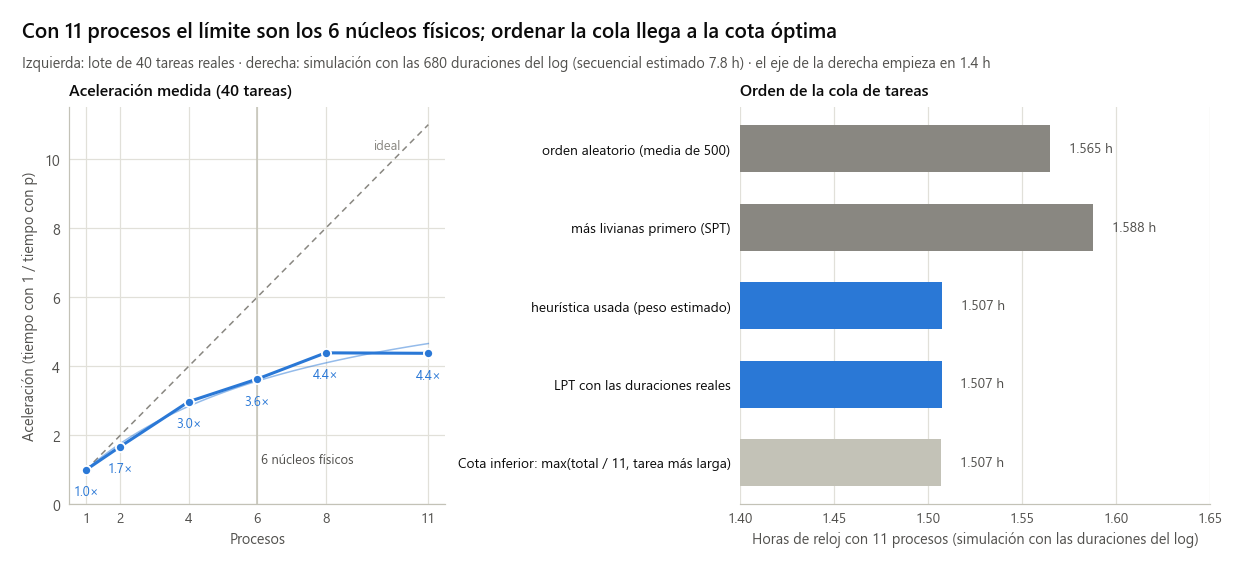

In [9]:
duraciones = log["tiempo_seg"].to_numpy()
pesos = np.array([_peso_tarea(r) for r in log[CLAVES].to_dict("records")])
rng = np.random.default_rng(config.RANDOM_STATE)
aleatorios = np.array([planificar(duraciones[rng.permutation(len(duraciones))], config.N_WORKERS) for _ in range(500)])
tabla26 = pd.DataFrame([
    ("Suma de las duraciones del log (CPU, medidas con 11 procesos)", duraciones.sum()),
    ("Secuencial estimado (1 proceso, sin contención)", duraciones.sum() / CONTENCION_11),
    ("11 procesos, orden aleatorio (media de 500)", aleatorios.mean()),
    ("11 procesos, más livianas primero (SPT)", planificar(np.sort(duraciones), config.N_WORKERS)),
    ("11 procesos, heurística usada (peso estimado)", planificar(duraciones[np.argsort(-pesos, kind="stable")], config.N_WORKERS)),
    ("11 procesos, LPT con las duraciones reales", planificar(np.sort(duraciones)[::-1], config.N_WORKERS)),
    ("Cota inferior: max(total / 11, tarea más larga)", max(duraciones.sum() / config.N_WORKERS, duraciones.max())),
], columns=["estrategia", "segundos"])
tabla26["horas"] = tabla26["segundos"] / 3600
tabla26["aceleracion_vs_secuencial_estimado"] = tabla26["segundos"].iloc[1] / tabla26["segundos"]
guardar_tabla(tabla26.round(4), "tabla26_planificacion_tareas")
display(tabla26.round(3))
print(f"Orden aleatorio: percentil 5–95 = {np.percentile(aleatorios, 5) / 3600:.3f}–{np.percentile(aleatorios, 95) / 3600:.3f} h")

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11, 4.3), width_ratios=[1, 1.25], layout="constrained")
p = aceleracion["procesos"]
ax_a.plot([1, 11], [1, 11], color=TINTA_3, lw=1, ls=(0, (4, 3)))
ax_a.text(9.4, 10.3, "ideal", color=TINTA_3, fontsize=8.5)
ax_a.axvline(6, color=EJE, lw=1)
ax_a.text(6.1, 1.2, "6 núcleos físicos", color=TINTA_2, fontsize=8.5)
malla = np.linspace(1, 11, 100)
ax_a.plot(malla, amdahl(malla, f_serial), color=AZUL, lw=1, alpha=0.5)
ax_a.plot(p, aceleracion["aceleracion"], "-o", color=AZUL, lw=2, ms=6, mec=FONDO, mew=1.2)
for xi, yi in zip(p, aceleracion["aceleracion"]):
    ax_a.text(xi, yi - 0.75, f"{yi:.1f}×", ha="center", fontsize=8.5, color=AZUL)
ax_a.set(xlabel="Procesos", ylabel="Aceleración (tiempo con 1 / tiempo con p)", title="Aceleración medida (40 tareas)",
         xlim=(0.5, 11.5), ylim=(0, 11.5))
ax_a.set_xticks(p)
ax_a.grid(True)
ax_a.set_axisbelow(True)

plan = tabla26.iloc[2:].reset_index(drop=True)
y = np.arange(len(plan))[::-1]
colores = [TINTA_3, TINTA_3, AZUL, AZUL, EJE]
ax_b.barh(y, plan["horas"], height=0.6, color=colores, zorder=2)
for yi, h in zip(y, plan["horas"]):
    ax_b.text(h + 0.01, yi, f"{h:.3f} h", va="center", fontsize=9, color=TINTA_2)
ax_b.set_yticks(y, labels=[e.replace("11 procesos, ", "") for e in plan["estrategia"]], fontsize=9)
ax_b.tick_params(axis="y", labelcolor=TINTA)
ax_b.set(xlim=(1.4, 1.65), xlabel="Horas de reloj con 11 procesos (simulación con las duraciones del log)",
         title="Orden de la cola de tareas")
ax_b.grid(axis="x")
ax_b.set_axisbelow(True)
ax_b.spines["left"].set_visible(False)
encabezado(fig, "Con 11 procesos el límite son los 6 núcleos físicos; ordenar la cola llega a la cota óptima",
           f"Izquierda: lote de 40 tareas reales · derecha: simulación con las 680 duraciones del log (secuencial estimado "
           f"{tabla26['horas'].iloc[1]:.1f} h) · el eje de la derecha empieza en 1.4 h")
guardar(fig, "fig31_paralelismo_y_planificacion")
plt.show()

> **Resultado:** la aceleración crece casi en línea recta hasta 4 procesos (3.0×) y después se aplana: 3.6× con 6 procesos y ≈ 4.4× con 8 y 11. La tabla explica por qué. El equipo tiene 6 núcleos físicos; los otros 6 núcleos lógicos son hilos de *hyperthreading* que comparten unidades de cálculo y memoria, así que con 11 procesos **cada tarea tarda ≈ 2.1 veces lo que tarda sola**: el trabajo total crece aunque se reparta. Además, con solo 40 tareas desiguales los procesos pasan parte del tiempo esperando al final (ocupación del 84% con 11 procesos). El ajuste de la ley de Amdahl resume ambos efectos como una fracción no paralelizable de ≈ 0.14 (techo de ≈ 7× en este lote). No es un problema del código sino del hardware: el paralelismo por procesos rinde hasta el número de núcleos físicos.
>
> Para el experimento completo, las duraciones del log ya se midieron con los 11 procesos en marcha (16.6 h "de CPU" incluyen ese enlentecimiento). Corrigiendo por el factor medido, el experimento en un solo proceso habría tardado ≈ 7.8 h, y con 11 procesos tardó ≈ 1.5 h de reloj: una aceleración de ≈ 5.2×, coherente con la medición del lote. El orden de la cola mejora menos, pero sin costo: en orden aleatorio el experimento tardaría en promedio 1.56 h; con la heurística que usa `run_experimentos.py` (que ni siquiera conoce las duraciones reales, solo un peso estimado por modelo) tarda 1.507 h, exactamente la cota inferior. La ganancia es chica (≈ 4%) porque hay 680 tareas y la más larga dura solo 9 minutos frente a 1.5 h por proceso; con muchas tareas cortas el orden importa poco. Poner las livianas primero (SPT) es la peor opción, porque deja las tareas largas para el final.

## 6. Implementación estándar frente a optimizada

Cada fila compara la opción "por defecto" con la que usa el proyecto, medida en este equipo con los hiperparámetros reales. La última columna indica si la optimización cambia el resultado del modelo.

In [10]:
def ajustar_rf_en_proceso(n_jobs):
    pipe = construir_modelo("clasificacion", "Random Forest", "sin_balanceo", HP["Random Forest"])
    pipe.set_params(modelo__n_jobs=n_jobs)
    pipe.fit(X_tr, y_tr)
    return True


def medir_comparaciones():
    filas = []

    def agregar(optimizacion, estandar, optimizada, t_std, t_opt, metrica_std="", metrica_opt=""):
        filas.append({"optimizacion": optimizacion, "estandar": estandar, "optimizada": optimizada,
                      "segundos_estandar": t_std, "segundos_optimizada": t_opt, "aceleracion": t_std / t_opt,
                      "resultado_estandar": metrica_std, "resultado_optimizada": metrica_opt})

    tiempos, aucs = {}, {}
    for metodo in ["exact", "hist"]:
        pipe = construir_modelo("clasificacion", "XGBoost", "sin_balanceo", HP["XGBoost"])
        pipe.set_params(modelo__tree_method=metodo)
        tiempos[metodo] = cronometrar(lambda: pipe.fit(X_tr, y_tr), 3)
        aucs[metodo] = roc_auc_score(y_te, pipe.predict_proba(X_te)[:, 1])
    agregar("XGBoost: búsqueda de cortes", "tree_method='exact'", "tree_method='hist'", tiempos["exact"], tiempos["hist"],
            f"AUC {aucs['exact']:.4f}", f"AUC {aucs['hist']:.4f}")
    for prob in [True, False]:
        pipe = construir_modelo("clasificacion", "SVM", "sin_balanceo", HP["SVM"])
        pipe.set_params(modelo__probability=prob)
        tiempos[prob] = cronometrar(lambda: pipe.fit(X_tr, y_tr), 3)
        puntaje = pipe.predict_proba(X_te)[:, 1] if prob else pipe.decision_function(X_te)
        aucs[prob] = roc_auc_score(y_te, puntaje)
    agregar("SVM: puntaje para el AUC", "probability=True (5 folds de Platt)", "decision_function", tiempos[True],
            tiempos[False], f"AUC {aucs[True]:.4f}", f"AUC {aucs[False]:.4f}")
    for algoritmo in ["auto", "brute"]:
        pipe = construir_modelo("clasificacion", "KNN", "sin_balanceo", HP["KNN"])
        pipe.set_params(modelo__algorithm=algoritmo).fit(X_tr, y_tr)
        tiempos[algoritmo] = cronometrar(lambda: pipe.predict_proba(X_te), 5)
        aucs[algoritmo] = roc_auc_score(y_te, pipe.predict_proba(X_te)[:, 1])
    agregar("KNN: búsqueda de vecinos (predicción)", "algorithm='auto' (elige árbol KD)", "algorithm='brute'",
            tiempos["auto"], tiempos["brute"], f"AUC {aucs['auto']:.4f}", f"AUC {aucs['brute']:.4f}")
    with Parallel(n_jobs=config.N_WORKERS) as paralelo:
        paralelo(delayed(ajustar_rf_en_proceso)(1) for _ in range(config.N_WORKERS))
        for n_jobs in [-1, 1]:
            t0 = time.perf_counter()
            paralelo(delayed(ajustar_rf_en_proceso)(n_jobs) for _ in range(2 * config.N_WORKERS))
            tiempos[f"rf{n_jobs}"] = time.perf_counter() - t0
    agregar("Random Forest con 11 procesos (22 ajustes)", "n_jobs=-1 dentro de cada proceso", "n_jobs=1 (sin anidar)",
            tiempos["rf-1"], tiempos["rf1"], "mismo modelo", "mismo modelo")
    import shap
    pipe = construir_modelo("clasificacion", "Random Forest", "ADASYN", HP["Random Forest"]).fit(X_tr, y_tr)
    bosque, prep = pipe.named_steps["modelo"], pipe.named_steps["prep"]
    Xt_tr, Xt_te = prep.transform(X_tr), prep.transform(X_te.iloc[:5])
    kernel = shap.KernelExplainer(lambda Z: bosque.predict_proba(Z)[:, 1], shap.kmeans(Xt_tr, 50))
    t0 = time.perf_counter()
    v_kernel = kernel.shap_values(Xt_te, nsamples=1000, silent=True)
    t_kernel = (time.perf_counter() - t0) / len(Xt_te)
    arbol = shap.TreeExplainer(bosque)
    t0 = time.perf_counter()
    v_arbol = np.asarray(arbol.shap_values(Xt_te))[..., 1]
    t_arbol = (time.perf_counter() - t0) / len(Xt_te)
    agregar("SHAP por vino (Random Forest)", "KernelExplainer (1,000 muestras)", "TreeExplainer (exacto)", t_kernel, t_arbol,
            f"aproximado (r = {np.corrcoef(np.ravel(v_kernel), np.ravel(v_arbol))[0, 1]:.3f} con el exacto)", "exacto")
    return pd.DataFrame(filas)


comparaciones = medido("comparaciones", medir_comparaciones)

espacios = {"clasificacion": ESPACIOS_CLASIFICACION, "regresion": ESPACIOS_REGRESION}


def tamano_grilla(espacio, puntos):
    n = 1
    for spec in espacio.values():
        n *= len(spec["categories"]) if spec["type"] == "categorical" else len(_valores_continuos(spec, puntos))
    return n


grid = log[log["optimizador"] == "Grid Search"].copy()
grid["exhaustiva"] = [tamano_grilla(espacios[t][m]["space"], 5) for t, m in zip(grid["tarea"], grid["modelo"])]
grid["segundos_exhaustiva"] = grid["tiempo_seg"] * (grid["exhaustiva"] * config.K_INNER + 1) / (grid["n_evaluaciones"] * config.K_INNER + 1)
tiempos_oof = pd.read_csv(RUTA_PREDICCIONES / "tiempos_reentrenamiento.csv")
cpu_oof = (tiempos_oof["t_fit_s"] + tiempos_oof["t_pred_s"]).sum()
diseno = pd.DataFrame([
    {"optimizacion": "Grid Search: tamaño de la grilla", "estandar": "5 valores por hiperparámetro continuo (hasta 3,125 puntos)",
     "optimizada": "grilla adaptativa (≤ 40 puntos)", "segundos_estandar": grid["segundos_exhaustiva"].sum(),
     "segundos_optimizada": grid["tiempo_seg"].sum(), "resultado_estandar": "estimado", "resultado_optimizada": "medido"},
    {"optimizacion": "Paralelismo por tareas (experimento completo)", "estandar": "1 proceso (estimado)",
     "optimizada": "11 procesos + orden LPT", "segundos_estandar": tabla26["segundos"].iloc[1],
     "segundos_optimizada": tabla26["segundos"].iloc[4],
     "resultado_estandar": "mismos resultados", "resultado_optimizada": "mismos resultados"},
    {"optimizacion": "Predicciones fuera de muestra para el análisis", "estandar": "repetir la validación anidada",
     "optimizada": "reentrenar con los hiperparámetros del log", "segundos_estandar": duraciones.sum(),
     "segundos_optimizada": cpu_oof, "resultado_estandar": "—", "resultado_optimizada": "idénticas (dif. ≤ 6e-17)"},
])
diseno["aceleracion"] = diseno["segundos_estandar"] / diseno["segundos_optimizada"]
tabla27 = pd.concat([comparaciones, diseno], ignore_index=True)
guardar_tabla(tabla27.round(5), "tabla27_estandar_vs_optimizada")
display(tabla27.assign(segundos_estandar=tabla27["segundos_estandar"].round(3),
                       segundos_optimizada=tabla27["segundos_optimizada"].round(3),
                       aceleracion=tabla27["aceleracion"].round(1)))

,optimizacion,estandar,optimizada,segundos_estandar,segundos_optimizada,aceleracion,resultado_estandar,resultado_optimizada
0,XGBoost: búsqueda de cortes,tree_method='exact',tree_method='hist',0.980,0.503,1.9,AUC 0.8748,AUC 0.8763
1,SVM: puntaje para el AUC,probability=True (5 folds de Platt),decision_function,1.216,0.210,5.8,AUC 0.8466,AUC 0.8466
2,KNN: búsqueda de vecinos (predicción),algorithm='auto' (elige árbol KD),algorithm='brute',0.061,0.023,2.7,AUC 0.8658,AUC 0.8658
3,Random Forest con 11 procesos (22 ajustes),n_jobs=-1 dentro de cada proceso,n_jobs=1 (sin anidar),5.778,5.356,1.1,mismo modelo,mismo modelo
4,SHAP por vino (Random Forest),"KernelExplainer (1,000 muestras)",TreeExplainer (exacto),0.651,0.074,8.8,aproximado (r = 0.991 con el exacto),exacto
5,Grid Search: tamaño de la grilla,5 valores por hiperparámetro continuo (hasta 3...,grilla adaptativa (≤ 40 puntos),325939.413,9950.434,32.8,estimado,medido
6,Paralelismo por tareas (experimento completo),1 proceso (estimado),11 procesos + orden LPT,28092.005,5426.788,5.2,mismos resultados,mismos resultados
7,Predicciones fuera de muestra para el análisis,repetir la validación anidada,reentrenar con los hiperparámetros del log,59678.880,1015.779,58.8,—,idénticas (dif. ≤ 6e-17)


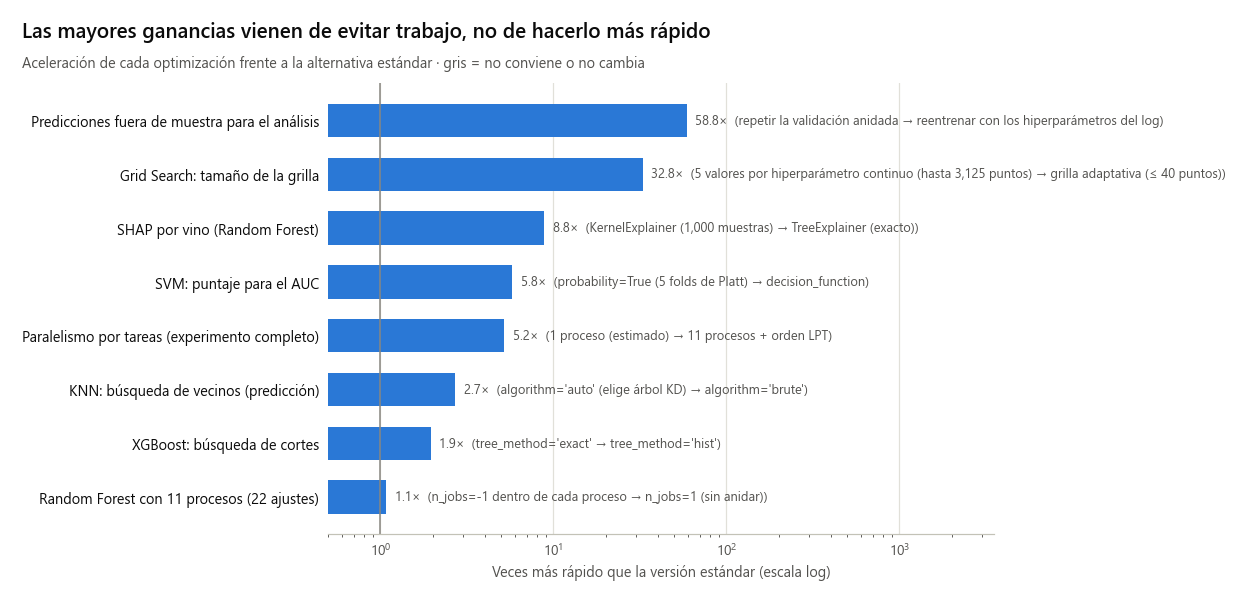

In [11]:
orden = tabla27.sort_values("aceleracion").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
y = np.arange(len(orden))
color = [AZUL if a >= 1.05 else TINTA_3 for a in orden["aceleracion"]]
ax.barh(y, orden["aceleracion"], height=0.62, color=color, zorder=2)
ax.axvline(1, color=TINTA_3, lw=1)
for yi, fila in zip(y, orden.itertuples()):
    ax.text(fila.aceleracion * 1.12, yi, f"{fila.aceleracion:,.1f}×  ({fila.estandar} → {fila.optimizada})",
            va="center", fontsize=8.4, color=TINTA_2)
ax.set_xscale("log")
ax.set_yticks(y, labels=orden["optimizacion"])
ax.tick_params(axis="y", labelcolor=TINTA)
ax.set(xlabel="Veces más rápido que la versión estándar (escala log)", xlim=(0.5, orden["aceleracion"].max() * 60))
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
encabezado(fig, "Las mayores ganancias vienen de evitar trabajo, no de hacerlo más rápido",
           "Aceleración de cada optimización frente a la alternativa estándar · gris = no conviene o no cambia")
guardar(fig, "fig32_estandar_vs_optimizada")
plt.show()

> **Resultado:**
> - **Evitar trabajo es lo que más rinde.** Reutilizar los hiperparámetros del log para reconstruir las predicciones fuera de muestra costó ≈ 17 minutos de CPU (menos de 2 minutos de reloj) en vez de repetir las 16.6 h de la validación anidada (59× menos), con exactamente las mismas métricas. La grilla adaptativa evita la explosión combinatoria de Grid Search: con 5 valores por hiperparámetro continuo, XGBoost necesitaría 3,125 puntos y Random Forest 375 por búsqueda, y solo la parte de Grid Search habría pasado de 2.8 h a ≈ 90 h (33×), aunque, como se vio en el notebook de resultados, a costa de una grilla gruesa en XGBoost.
> - **Paralelizar al nivel correcto.** Repartir tareas completas entre 11 procesos acelera ≈ 5× en este equipo de 6 núcleos físicos; agregar además hilos dentro de cada Random Forest (`n_jobs=-1`) no ayuda y es ≈ 8% más lento (5.78 s frente a 5.36 s para 22 ajustes), porque los núcleos ya están ocupados y los hilos solo compiten entre sí (sobresuscripción). Por eso el proyecto fija `n_jobs=1` en los estimadores.
> - **Elegir bien el algoritmo.** `tree_method='hist'` hace a XGBoost ≈ 2 veces más rápido con el mismo AUC, y usar `decision_function` en SVM evita los 5 ajustes internos de Platt (≈ 6 veces más rápido, mismo AUC). Para explicar el Random Forest, TreeExplainer es ≈ 9 veces más rápido que KernelExplainer y además exacto (KernelExplainer da una aproximación con r = 0.99).
> - **Lo "optimizado" no siempre gana.** En KNN, `algorithm='auto'` elige un árbol KD, pero con 13 variables y ≈ 4,000 vinos la fuerza bruta (multiplicación de matrices optimizada) predice más rápido. Las estructuras de datos sofisticadas convienen con muchas filas y pocas dimensiones.

## 7. Costo de usar los modelos

Una vez elegido, el modelo se entrena una vez y se usa para predecir. Se mide el tamaño del modelo serializado, el tiempo de entrenamiento con los 4,256 vinos del fold y la latencia para puntuar 1,000 vinos nuevos.

In [12]:
def medir_uso():
    filas = []
    X_nuevos = X_te.iloc[:1000]
    combos = [(f.modelo, f.balanceo, f.optimizador, "clasificacion") for f in mejores.itertuples()]
    combos.append(("Random Forest", "no_aplica", "Grid Search", "regresion"))
    for modelo, balanceo, optimizador, tarea in combos:
        log = log_clf if tarea == "clasificacion" else log_reg
        y = y_tr if tarea == "clasificacion" else y_reg.iloc[tr0].reset_index(drop=True)
        pipe = construir_modelo(tarea, modelo, balanceo, hiperparametros(log, modelo, balanceo, optimizador))
        t_fit = cronometrar(lambda: pipe.fit(X_tr, y), 3)
        predecir = pipe.predict_proba if tarea == "clasificacion" and hasattr(pipe, "predict_proba") else (
            pipe.decision_function if tarea == "clasificacion" else pipe.predict)
        t_pred = cronometrar(lambda: predecir(X_nuevos), 5)
        filas.append({"tarea": tarea, "modelo": modelo, "balanceo": balanceo, "optimizador": optimizador,
                      "entrenamiento_s": t_fit, "ms_por_1000_vinos": 1000 * t_pred, "tamano_MB": tamano_en_memoria(pipe)})
    return pd.DataFrame(filas)


tabla28 = medido("uso_de_modelos", medir_uso)
guardar_tabla(tabla28.round(4), "tabla28_costo_de_uso")
display(tabla28.round(3))

,tarea,modelo,balanceo,optimizador,entrenamiento_s,ms_por_1000_vinos,tamano_MB
0,clasificacion,Random Forest,class_weight,Bayesiano,1.870,61.111,28.603
1,clasificacion,XGBoost,class_weight,Bayesiano,0.501,10.561,2.140
2,clasificacion,SVM,class_weight,Bayesiano,0.293,102.711,0.269
3,clasificacion,KNN,sin_balanceo,Bayesiano,0.009,59.741,0.548
4,clasificacion,Regresión Logística (L1/L2),sin_balanceo,Bayesiano,0.011,2.549,0.003
5,clasificacion,Decision Tree,class_weight,Bayesiano,0.018,2.521,0.009
6,clasificacion,Naive Bayes,class_weight,Grid Search,0.007,2.705,0.003
7,regresion,Random Forest,no_aplica,Grid Search,2.505,93.662,82.426


> **Resultado:** en uso, todos los modelos son baratos: el más lento puntúa 1,000 vinos en una fracción de segundo. La diferencia está en la memoria: el Random Forest recomendado ocupa decenas de MB (cientos de árboles profundos), XGBoost unos pocos MB y los modelos lineales o Naive Bayes unos KB. KNN guarda todo el conjunto de entrenamiento. Para un sistema que puntúe vinos en línea cualquiera sirve; si el tamaño importara (por ejemplo, en un dispositivo pequeño), XGBoost daría casi el mismo AUC con un modelo mucho más liviano.

## 8. Conclusiones del costo computacional

1. **El costo está concentrado:** Random Forest y XGBoost se llevan el 77% de las 16.6 h de CPU (79,505 modelos entrenados) y SVM otro 17%. El costo medio de un ajuste varía casi dos órdenes de magnitud entre modelos.
2. **La complejidad teórica se cumple en la práctica:** SVM escala con exponente ≈ 2 y sería el primero en volverse inviable con más datos; los árboles y XGBoost escalan de forma casi lineal; KNN es barato al entrenar pero caro al predecir.
3. **El perfilamiento muestra que el tiempo está en código compilado** (≈ 70% en la construcción de árboles en Cython, ≈ 85% en el núcleo C++ de XGBoost), con un sobrecosto de Python por árbol que en Random Forest llega a casi una cuarta parte. Remuestreo, preprocesamiento y predicción pesan poco. Las mejoras posibles son estructurales: menos ajustes y más paralelismo.
4. **Las optimizaciones que hacen viable el proyecto** son, en orden de impacto: reutilizar resultados en lugar de recalcular (59×), acotar la grilla (33× en Grid Search), paralelizar por tareas sin anidar hilos (≈ 5× con 11 procesos en 6 núcleos físicos), ordenar la cola con LPT (llega a la cota óptima) y elegir algoritmos eficientes (`hist` en XGBoost, `decision_function` en SVM, TreeExplainer para SHAP).